# ☁️ GCP Cloud Computing — Zero to Hero
### Beginner-Friendly Google Colab / Jupyter Training Module

**Audience:** Students starting GCP from scratch  
**Teaching style:** Concept → analogy → visualization → CLI/UI demo → practice → real-world scenario → quiz

This notebook expands the supplied GCP syllabus into a structured learning path covering:

1. Cloud computing fundamentals
2. Public / Private / Hybrid Cloud
3. Cloud vocabulary
4. GCP global infrastructure
5. Projects, billing, budgets and APIs
6. IAM and service accounts
7. Compute Engine, SSH, startup scripts, firewalls and images
8. Cloud Storage and storage classes
9. VM ↔ GCS secure access
10. Managed Instance Groups and Load Balancing
11. VPC, subnets, Cloud NAT and private applications
12. Custom domains and Cloud DNS
13. `gcloud` CLI
14. Observability, security and cost-awareness
15. Mini projects and interview questions

> ⚠️ **Important:** This notebook is designed to teach and demonstrate concepts safely. Cloud commands that create billable resources are provided for controlled lab use. Always check your project, billing and cleanup steps before running them.


## 0. Learning Roadmap

```text
Cloud Basics
     ↓
GCP Global Infrastructure
     ↓
Project + Billing + APIs
     ↓
IAM + Service Accounts
     ↓
Compute Engine
     ↓
Cloud Storage
     ↓
VPC + Networking
     ↓
MIG + Health Checks
     ↓
Load Balancer
     ↓
Cloud DNS + Domain
     ↓
gcloud Automation
     ↓
Production Thinking
```

### Mental model

Think of GCP as a **city**:

- **Organization** → country/company
- **Folder** → department
- **Project** → one business/application workspace
- **Region** → geographical area
- **Zone** → isolated location inside a region
- **VM** → rented computer
- **Bucket** → storage warehouse
- **IAM** → security guard
- **Load Balancer** → traffic controller
- **Cloud NAT** → controlled internet exit for private VMs


# 1. What is Cloud Computing?

Cloud computing means consuming computing resources over the internet instead of buying and maintaining all physical infrastructure yourself.

### Traditional IT

```text
Company
  ↓
Buy Servers → Install OS → Configure Network → Maintain Hardware
  ↓
Large upfront investment
```

### Cloud

```text
User
  ↓ Internet
Cloud Provider
  ├── Compute
  ├── Storage
  ├── Database
  ├── Networking
  └── AI/ML services
```

### Simple example

Instead of buying a server costing ₹2,00,000 for a temporary project, you can rent cloud compute for the period you need it.

**Core idea:** on-demand resources + internet access + managed infrastructure + usage-based pricing.


## 1.1 Public vs Private vs Hybrid Cloud

| Model | Simple meaning | Example use |
|---|---|---|
| Public | Shared provider infrastructure | Startup web application |
| Private | Dedicated environment for one organization | Strict internal workloads |
| Hybrid | Combination of private + public | Sensitive data private, scalable app public |

### Remember

**Public = shared provider environment**  
**Private = dedicated organization environment**  
**Hybrid = combination**

The cloud vocabulary also includes virtualization, VMs, APIs, regions, zones, scalability, elasticity, HA, fault tolerance, disaster recovery and load balancing.


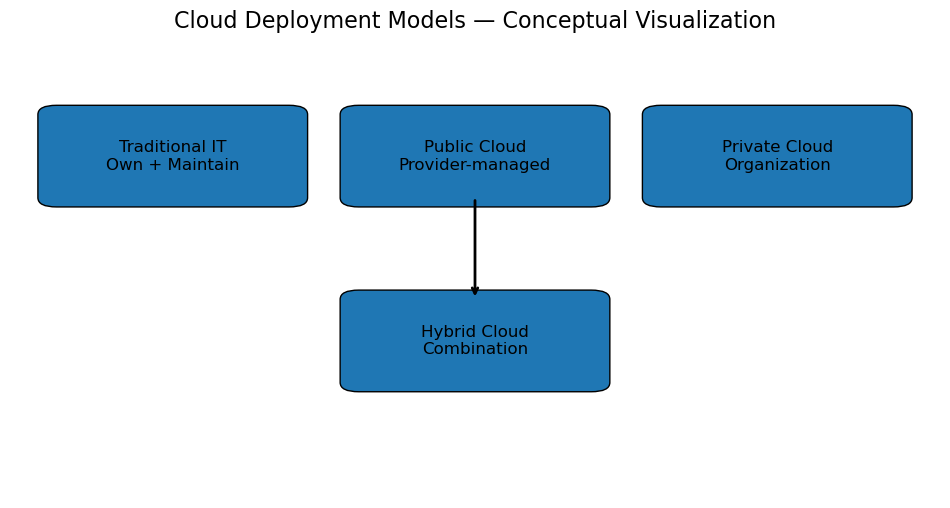

In [1]:
# Optional: create a simple conceptual diagram using matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 6))
ax.axis("off")

boxes = [
    (0.05, 0.65, 0.25, 0.18, "Traditional IT\nOwn + Maintain"),
    (0.375, 0.65, 0.25, 0.18, "Public Cloud\nProvider-managed"),
    (0.70, 0.65, 0.25, 0.18, "Private Cloud\nOrganization"),
    (0.375, 0.25, 0.25, 0.18, "Hybrid Cloud\nCombination"),
]
for x, y, w, h, label in boxes:
    ax.add_patch(FancyBboxPatch((x,y), w,h, boxstyle="round,pad=0.02"))
    ax.text(x+w/2, y+h/2, label, ha="center", va="center", fontsize=12)

ax.annotate("", xy=(0.50,0.43), xytext=(0.50,0.65),
            arrowprops=dict(arrowstyle="->", lw=2))
ax.set_title("Cloud Deployment Models — Conceptual Visualization", fontsize=16)
plt.show()


# 2. GCP Global Infrastructure

## Region

A **region** is a geographical area containing GCP resources and zones.

## Zone

A **zone** is an isolated deployment location within a region.

### Why does this matter?

If an application runs in only one location, a failure there can affect the application.

```text
Region: asia-south1
 ├── Zone A
 ├── Zone B
 └── Zone C

       ↓

Multi-zone application
       ↓
Higher availability
```

### Key terms

- **Scalability:** ability to handle more workload
- **Elasticity:** dynamically add/remove resources based on demand
- **High Availability:** minimize downtime
- **Fault Tolerance:** continue operating despite failures
- **Disaster Recovery:** restore service/data after a major incident
- **Load Balancing:** distribute traffic across healthy backends


# 3. GCP Resource Hierarchy

```text
Organization
    │
    ├── Folder
    │     ├── Project A
    │     └── Project B
    │
    └── Folder
          └── Project C
                ├── VM
                ├── Bucket
                ├── VPC
                └── Database
```

### Why Projects?

A project is the main workspace where resources are organized. It also provides an important boundary for APIs, IAM and billing relationships.

### Teaching analogy

A project is like a **college department**:

- Department has students/resources
- IAM controls who can access them
- APIs enable capabilities
- Billing tracks cloud consumption


# 4. Billing, Budgets and Cost Awareness

Before creating resources:

### Checklist

- [ ] Correct project selected
- [ ] Billing account understood
- [ ] Budget created
- [ ] Alerts configured
- [ ] Lab resources have names/tags
- [ ] Cleanup plan ready

### Important distinction

**Budget alert ≠ automatic shutdown**

A budget helps you monitor and receive alerts. It does not by itself guarantee that resources will stop.

### Safe student practice

Use a dedicated lab project such as:

```text
gcp-training-student-01
```

and clean resources after each lab.


# 5. APIs

Many GCP services are exposed through APIs.

Think:

```text
Your command / Console
        ↓
GCP API
        ↓
Cloud Service
```

Examples:

- Compute Engine API
- Cloud Storage API
- Cloud Logging API
- Cloud Monitoring API
- Cloud Resource Manager API

### Conceptual command

```bash
gcloud services enable compute.googleapis.com
```

The same underlying cloud APIs are used whether you work through Console, CLI, SDKs or automation tools.


# 6. IAM — Who Can Do What?

IAM answers:

> **Who can do what on which resource?**

```text
Identity
   ↓
Role
   ↓
Permissions
   ↓
Resource
```

### Example

```text
student@example.com
        ↓
Storage Object Viewer
        ↓
Can read objects
        ↓
training-bucket
```

### Role types

| Role | Meaning |
|---|---|
| Basic | Broad legacy roles |
| Predefined | Google-managed fine-grained roles |
| Custom | Organization-defined permissions |

### Best practice

**Least privilege:** give only the permissions required for the task.


## 6.1 Service Accounts

A service account is a non-human identity used by applications, VMs, scripts and automation.

Example:

```text
Compute Engine VM
      ↓
Service Account
      ↓
IAM permissions
      ↓
Cloud Storage bucket
```

This avoids embedding user credentials inside applications.

### Production mindset

Prefer short-lived credentials / workload identity mechanisms where supported, and avoid unnecessary long-lived service-account keys.


# 7. Compute Engine — Your Cloud VM

Compute Engine is GCP's IaaS service for running virtual machines.

### VM anatomy

```text
VM
├── Machine type → CPU + RAM
├── Boot disk → OS
├── Network interface
├── Internal IP
├── Optional external IP
├── Service account
└── Firewall controls
```

### Common student exercise

1. Create VM
2. SSH
3. Install NGINX
4. Test locally
5. Create firewall rule
6. Test externally
7. Delete VM


In [ ]:
# Cloud Shell / local terminal example
# Review before running. Replace variables first.

PROJECT_ID="<YOUR_PROJECT_ID>"
REGION="asia-south1"
ZONE="asia-south1-a"

# Configure
gcloud config set project "$PROJECT_ID"
gcloud config set compute/region "$REGION"
gcloud config set compute/zone "$ZONE"

# Verify
gcloud config list
gcloud auth list


In [ ]:
# Create a small Debian VM for a controlled lab
gcloud compute instances create day4-demo-vm \
  --zone="$ZONE" \
  --machine-type=e2-micro \
  --image-family=debian-12 \
  --image-project=debian-cloud


In [ ]:
# SSH
gcloud compute ssh day4-demo-vm --zone="$ZONE"

# Inside the VM:
# sudo apt-get update
# sudo apt-get install -y nginx
# curl http://localhost


## 7.1 Startup Scripts

Manual:

```text
Create VM
   ↓
SSH
   ↓
Install software manually
```

Automated:

```text
Create VM
   ↓
Startup Script
   ↓
Install/configure application
   ↓
Ready
```

Startup scripts are a first step toward configuration automation and Infrastructure as Code thinking.


In [ ]:
#!/bin/bash
# Example startup script — place this in an instance template or VM metadata.

apt-get update -y
apt-get install -y nginx
systemctl enable nginx
systemctl start nginx

echo "Hello from GCP Startup Script - $(hostname)" > /var/www/html/index.html


## 7.2 Firewall Concept

A firewall controls network traffic.

```text
Internet
   │
   │ TCP:80
   ▼
Firewall Rule
   │
   ▼
VM
   │
   ▼
NGINX :80
```

Do not expose every port publicly.

**Good practice:** allow only the required protocol, port, source range and targets.


# 8. Cloud Storage (GCS)

Cloud Storage is GCP's object storage service.

### Object storage mental model

```text
Bucket
 ├── object: data.csv
 ├── object: model.pkl
 ├── object: logs.txt
 └── object: backup.zip
```

A bucket is the container; an object is the stored data plus metadata.

### Common use cases

- Backups
- Logs
- Dataset storage
- ML artifacts
- CI/CD artifacts
- Static assets
- Data lake landing zones

GCS provides high durability and multiple storage classes for different access patterns.


## 8.1 Storage Classes

| Class | Typical use |
|---|---|
| Standard | Frequently accessed |
| Nearline | Infrequent access |
| Coldline | Less frequent access |
| Archive | Long-term archival |

### Decision rule

```text
Frequent access → Standard
Less frequent → Nearline
Rare → Coldline
Very rare / archive → Archive
```

Always evaluate retrieval and operation costs along with storage price.


In [ ]:
# GCS CLI practice
BUCKET="gcp-training-$RANDOM-$RANDOM"

# Create
gcloud storage buckets create "gs://$BUCKET" --location="$REGION"

# Create local file
echo "Hello from GCP training" > hello.txt

# Upload
gcloud storage cp hello.txt "gs://$BUCKET/hello.txt"

# List
gcloud storage ls "gs://$BUCKET"

# Read
gcloud storage cat "gs://$BUCKET/hello.txt"


In [ ]:
# Cleanup this bucket after the lab
gcloud storage rm "gs://$BUCKET/hello.txt"
gcloud storage buckets delete "gs://$BUCKET"


# 9. Compute Engine + GCS Secure Access

### Real-world architecture

```text
                 IAM
                  │
                  ▼
VM ─────────── Service Account ───────────► GCS Bucket
│                                               │
└── Application                                 └── Objects
```

The VM can use its attached identity rather than storing a username/password or long-lived storage key inside the VM.

### Example

```bash
gcloud storage ls gs://YOUR_BUCKET
gcloud storage cp gs://YOUR_BUCKET/hello.txt hello-vm.txt
```

### Teaching point

**Authentication:** Who are you?  
**Authorization:** What are you allowed to do?


# 10. Managed Instance Groups (MIG)

A MIG manages a group of similar VM instances.

```text
                 Load Balancer
                       │
          ┌────────────┼────────────┐
          ▼            ▼            ▼
        VM-1          VM-2         VM-3
          │            │            │
       Zone A        Zone B       Zone C
```

Benefits:

- Automated instance management
- Autoscaling
- Autohealing
- Consistent instance templates
- Multi-zone deployments


# 11. Health Checks + Load Balancing

A health check asks:

```text
Is backend healthy?
       ↓
    YES → send traffic
    NO  → stop sending traffic
```

### Production-style flow

```text
User
  ↓
Global/Regional Load Balancer
  ↓
Health Check
  ↓
Healthy Backend
  ↓
MIG
  ├── VM A
  ├── VM B
  └── VM C
```

This is the foundation of highly available web applications.


In [ ]:
# Example: create a health check
gcloud compute health-checks create http web-health-check \
  --port=80


# 12. VPC Networking

A VPC is your virtual network in GCP.

### Typical architecture

```text
                    Internet
                       │
                 Load Balancer
                       │
                Proxy-only subnet
                       │
                 Private app subnet
                  ┌────┴────┐
                  │         │
                 VM1       VM2
                  │         │
                  └────┬────┘
                       │
                  Cloud NAT
                       │
                    Internet
```

### Important components

- VPC
- Subnet
- Routes
- Firewall rules
- Cloud Router
- Cloud NAT
- Load Balancer
- Proxy-only subnet for applicable regional proxy-based load balancing architectures


## 12.1 Public vs Private VM

### Public VM

```text
Internet → External IP → VM
```

### Private VM

```text
Internet
   ✕
   │
Private VM
   │
Cloud NAT → Internet (outbound)
```

A private VM can access the internet for updates through NAT without needing an external IP, while inbound access can remain restricted.


# 13. Regional External Application Load Balancer + Private Flask App

### Architecture

```text
                 Internet
                    │
              External IP
                    │
        Regional Application LB
                    │
            Proxy-only subnet
                    │
             Health Check / 8080
                    │
              Private MIG
              ┌─────┴─────┐
             VM1         VM2
              │            │
              └──────┬─────┘
                     │
                 Cloud NAT
```

### Flask application

```python
from flask import Flask

app = Flask(__name__)

@app.route("/")
def index():
    return "Hello from private Flask app!"

@app.route("/health")
def health():
    return "ok", 200
```

### Why `/health`?

A load balancer needs a predictable endpoint to determine whether the application is healthy.


# 14. DNS and Custom Domain

DNS translates names to IP addresses.

```text
example.in
    ↓ DNS
External Load Balancer IP
    ↓
Application
```

### Typical setup

```text
Domain Registrar
      ↓
Nameservers
      ↓
Cloud DNS Public Zone
      ↓
A record
      ↓
Load Balancer IP
```

For HTTPS production deployments, add managed TLS certificates and redirect HTTP to HTTPS.


# 15. gcloud CLI Deep Dive

The Console is excellent for learning and exploration.

The CLI is essential for automation and repeatability.

### Core pattern

```bash
gcloud <service> <resource> <action>
```

Examples:

```bash
gcloud compute instances list
gcloud compute instances describe VM_NAME
gcloud storage ls
gcloud projects describe PROJECT_ID
```

### Configuration

```bash
gcloud auth list
gcloud config list
gcloud config set project PROJECT_ID
gcloud config set compute/region REGION
gcloud config set compute/zone ZONE
```


In [ ]:
# Useful discovery commands
gcloud projects list
gcloud compute regions list
gcloud compute zones list --filter="region:($REGION)"
gcloud compute instances list
gcloud storage ls


# 16. Console vs CLI vs Terraform

| Tool | Best for |
|---|---|
| Console | Learning, visual exploration, one-off tasks |
| gcloud | CLI automation and scripting |
| Terraform | Declarative Infrastructure as Code |
| Python SDK | Application-driven automation |
| CI/CD | Repeatable delivery pipelines |

### Evolution

```text
Manual Console
      ↓
gcloud CLI
      ↓
Scripts
      ↓
Terraform / IaC
      ↓
CI/CD + Policy + Observability
```


# 17. Observability

Production cloud systems need visibility.

### Three pillars

```text
        Observability
        /     |      \
     Logs   Metrics   Traces
```

### GCP examples

- Cloud Logging
- Cloud Monitoring
- Alerting
- Load balancer logs
- VM/application logs

### Simple question

If a user says **"the website is slow"**, you need evidence:

- CPU?
- Memory?
- Request latency?
- Error rate?
- Backend health?
- Network?
- Database?


# 18. Security Checklist

Before calling a GCP deployment production-ready:

- [ ] Least-privilege IAM
- [ ] No unnecessary public IPs
- [ ] Restricted firewall rules
- [ ] Service accounts for workloads
- [ ] Secrets stored securely
- [ ] HTTPS/TLS enabled
- [ ] Logging enabled
- [ ] Monitoring and alerts configured
- [ ] Backups tested
- [ ] Budget alerts configured
- [ ] Resources tagged/labeled
- [ ] Cleanup policy defined


# 19. Mini Project 1 — Static Asset / Backup Bucket

### Problem

A company needs a central place for application backups.

### Design

```text
Application
    ↓
Cloud Storage Bucket
    ↓
Lifecycle Policy
    ↓
Cheaper storage class over time
```

### Student tasks

1. Create a bucket.
2. Upload 3 files.
3. List objects.
4. Download an object.
5. Inspect metadata.
6. Configure a lifecycle rule.
7. Delete the test resources.


# 20. Mini Project 2 — Highly Available Web App

### Problem

A web application should survive a VM failure.

### Expected architecture

```text
                 Users
                   │
             Load Balancer
                   │
          ┌────────┴────────┐
          │                 │
        MIG Zone A        MIG Zone B
          │                 │
         VM(s)             VM(s)
          │                 │
          └──── Health Checks ────┘
```

### Student tasks

- Create instance template
- Add startup script
- Create MIG
- Add health check
- Configure load balancer
- Test application
- Stop/remove one backend
- Observe recovery
- Inspect logs


# 21. Mini Project 3 — Private Flask Application

### Problem

A company wants its application VMs to have **no external IPs**.

### Solution

```text
Internet
   ↓
Regional External Application LB
   ↓
Proxy-only subnet
   ↓
Private MIG
   ↓
Flask :8080
   ↓
Cloud NAT for outbound package updates
```

### Student tasks

1. Create custom VPC.
2. Create app subnet.
3. Create proxy-only subnet where required.
4. Configure Cloud NAT.
5. Create firewall rules.
6. Build Flask startup script.
7. Create private MIG.
8. Configure health check.
9. Configure load balancer.
10. Test `/` and `/health`.


# 22. Knowledge Check

### Q1. What does IAM answer?

A. How much storage exists?  
B. Who can do what on which resource?  
C. Which region is cheapest?  
D. How many CPUs are installed?

**Answer:** B

### Q2. Which service is object storage?

A. Compute Engine  
B. Cloud Storage  
C. Cloud DNS  
D. Cloud NAT

**Answer:** B

### Q3. What does a health check do?

A. Creates users  
B. Checks backend availability  
C. Stores files  
D. Creates a billing account

**Answer:** B

### Q4. Why use a MIG?

A. To store objects  
B. To manage a group of similar VMs  
C. To register a domain  
D. To replace IAM

**Answer:** B

### Q5. What is Cloud NAT useful for?

A. Giving every VM a public IP  
B. Allowing private resources controlled outbound internet access  
C. Replacing DNS  
D. Creating buckets

**Answer:** B


# 23. Interview Questions

1. What is the difference between a region and a zone?
2. What is the difference between scalability and elasticity?
3. Explain IAM using the "who → what → resource" model.
4. User identity vs service account?
5. Why is least privilege important?
6. What is the difference between object and block storage?
7. Why would you use a MIG?
8. What is the purpose of a health check?
9. What is a load balancer?
10. Why use a private VM?
11. How can a private VM access the internet without an external IP?
12. What is Cloud NAT?
13. What is a VPC?
14. What is a proxy-only subnet?
15. What is DNS?
16. Console vs `gcloud`?
17. Why use Terraform after learning `gcloud`?
18. What is the difference between authentication and authorization?
19. How would you design a highly available web application?
20. How would you reduce accidental GCP costs in a student lab?


# 24. Final End-to-End Architecture

```text
                         USERS
                           │
                           ▼
                    DNS / Domain
                           │
                           ▼
                External Load Balancer
                           │
                    Health Checks
                           │
                           ▼
                 ┌─────────────────┐
                 │      MIG        │
                 │ ┌────┐  ┌────┐  │
                 │ │VM1 │  │VM2 │  │
                 │ └────┘  └────┘  │
                 └───────┬─────────┘
                         │
                    Private VPC
                         │
                    Cloud NAT
                         │
                      Internet

          Application ─────────► Cloud Storage
                │                      │
                ▼                      ▼
             Logs                  Backups
                │
                ▼
        Cloud Logging/Monitoring

IAM + Service Accounts + Firewall + Budget
              │
              ▼
        Security & Governance
```

## The student's learning journey

```text
Beginner
  ↓
Cloud Concepts
  ↓
GCP Console
  ↓
Projects + Billing
  ↓
IAM
  ↓
VMs
  ↓
Storage
  ↓
Networking
  ↓
High Availability
  ↓
Load Balancing
  ↓
DNS
  ↓
gcloud
  ↓
Automation / IaC
  ↓
Production Cloud Engineer
```


# 🎓 Instructor Notes

### Recommended teaching sequence

**Session 1:** Cloud + GCP fundamentals  
**Session 2:** Projects + Billing + APIs  
**Session 3:** IAM + Service Accounts  
**Session 4:** Compute Engine  
**Session 5:** Cloud Storage  
**Session 6:** VM + GCS integration  
**Session 7:** MIG + Load Balancing  
**Session 8:** VPC + private applications  
**Session 9:** DNS + custom domain  
**Session 10:** `gcloud` + automation  
**Session 11:** Observability + security + cost  
**Session 12:** Capstone project + interview preparation

### Teaching method

For every concept use:

**WHY → WHAT → ARCHITECTURE → DEMO → HANDS-ON → FAILURE CASE → CLEANUP → INTERVIEW QUESTION**

This helps beginners understand not only *what command to run*, but **why the architecture exists**.


# 🧹 Final Cleanup Checklist

At the end of every practical:

```bash
# Inspect resources first
gcloud compute instances list
gcloud compute instance-groups managed list
gcloud compute backend-services list --global
gcloud storage ls
```

Then delete resources that were created only for the lab.

> Never delete a shared/production resource just because it appears in your project. Confirm ownership before cleanup.

---

## 🎯 Final Goal

By completing this notebook, students should be able to explain and build the basic path:

**Cloud → GCP → Project → IAM → VM → Storage → VPC → MIG → Load Balancer → DNS → CLI → Automation**

That is the foundation on which Kubernetes/GKE, Terraform, CI/CD, monitoring, security and cloud-native application development can be taught next.
